## **Experiment 08:** CNN and Transfer Learning (Wine Dataset)

**Course:** ICE 4111: Artificial Intelligence Lab  
**Student Name:** ______________________  **Student ID:** ______________________

**Objective:** Compare a small CNN from scratch with a frozen pretrained VGG16 on the small **Wine** dataset (178 wines, 13 chemical measurements, 3 classes: class_0, class_1, class_2; built into scikit-learn, no download needed).

**Note:** Wine is *tabular* data, not images. To use CNN and VGG16 we reshape each row of 13 features (padded to 16) into a tiny 4x4 grayscale 'image'.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_wine
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
print("Setup complete. You can start the experiment.")

Setup complete. You can start the experiment.


In [2]:
# Load the Wine dataset (built into scikit-learn, no internet needed)
wine = load_wine()
X_tab, y = wine.data, wine.target
class_names = list(wine.target_names)

print("Shape:", X_tab.shape)
print("Class counts:", np.bincount(y))
pd.DataFrame(X_tab, columns=wine.feature_names).head()

Shape: (178, 13)
Class counts: [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


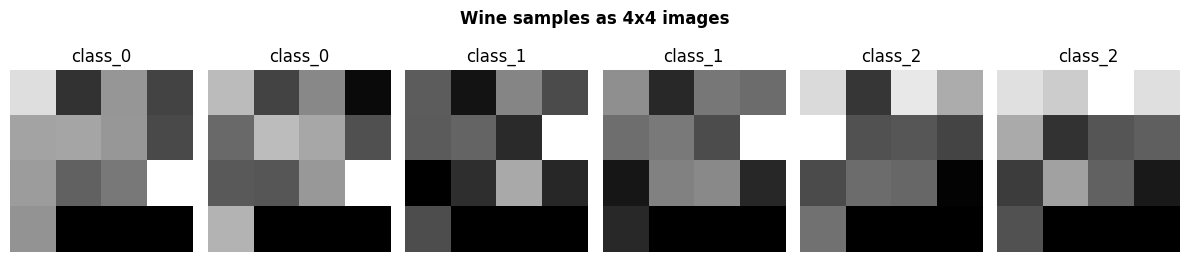

In [3]:
# Scale every feature to 0-1, pad 13 -> 16 features, reshape to 4x4 'images'
# (fit the scaler on the full set only for simplicity in this lab)
X_scaled = MinMaxScaler().fit_transform(X_tab).astype("float32")
X = np.pad(X_scaled, ((0, 0), (0, 3))).reshape(-1, 4, 4)

fig, axes = plt.subplots(1, 6, figsize=(12, 2.8))
for ax, i in zip(axes, [0, 1, 60, 61, 130, 131]):
    ax.imshow(X[i], cmap="gray")
    ax.set_title(class_names[y[i]])
    ax.axis("off")
plt.suptitle("Wine samples as 4x4 images", fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
# Train / Validation / Test split
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)

X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]
print("Train:", X_train_cnn.shape, "Val:", X_val_cnn.shape, "Test:", X_test_cnn.shape)

Train: (113, 4, 4, 1) Val: (29, 4, 4, 1) Test: (36, 4, 4, 1)


In [5]:
# Small CNN for 4x4x1 inputs
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4, 4, 1)),
    tf.keras.layers.Conv2D(16, 2, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(32, 2, padding="same", activation="relu"),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax"),
])
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 4, 4, 16)       │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,675 (72.95 KB)

 Trainable params: 18,675 (72.95 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=100, batch_size=16, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
)
print(f"CNN training completed after {len(cnn_history.history['loss'])} epochs.")

CNN training completed after 100 epochs.


In [7]:
cnn_test_pred = np.argmax(cnn_model.predict(X_test_cnn, verbose=0), axis=1)
cnn_accuracy = accuracy_score(y_test, cnn_test_pred)
print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(classification_report(y_test, cnn_test_pred, target_names=class_names))

CNN Test Accuracy: 0.9722
              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



In [8]:
# Prepare for VGG16: grayscale -> 3 channels, resize 4x4 -> 32x32 (VGG16 minimum size).
# VGG16's preprocess_input expects 0-255 pixels, so scale back up by 255.
def resize_for_transfer(images):
    rgb = np.repeat(images[..., np.newaxis], 3, axis=-1) * 255.0
    return tf.image.resize(rgb, (32, 32), method="nearest").numpy()

X_train_tl = resize_for_transfer(X_train)
X_val_tl = resize_for_transfer(X_val)
X_test_tl = resize_for_transfer(X_test)
print("Transfer learning input shape:", X_train_tl.shape)

Transfer learning input shape: (113, 32, 32, 3)


In [9]:
base_model = tf.keras.applications.VGG16(
    input_shape=(32, 32, 3), include_top=False, weights="imagenet")
base_model.trainable = False

transfer_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Lambda(tf.keras.applications.vgg16.preprocess_input),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax"),
])
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"])
transfer_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 1, 1, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,747,715 (56.26 MB)

 Trainable params: 33,027 (129.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
transfer_history = transfer_model.fit(
    X_train_tl, y_train,
    validation_data=(X_val_tl, y_val),
    epochs=50, batch_size=16, verbose=0,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
)
print(f"VGG16 training completed after {len(transfer_history.history['loss'])} epochs.")

VGG16 training completed after 31 epochs.


In [11]:
transfer_test_pred = np.argmax(transfer_model.predict(X_test_tl, verbose=0), axis=1)
transfer_accuracy = accuracy_score(y_test, transfer_test_pred)
print(f"Transfer Learning Test Accuracy: {transfer_accuracy:.4f}")
print(classification_report(y_test, transfer_test_pred, target_names=class_names, zero_division=0))

Transfer Learning Test Accuracy: 0.8333
              precision    recall  f1-score   support

     class_0       0.85      0.92      0.88        12
     class_1       0.79      0.79      0.79        14
     class_2       0.89      0.80      0.84        10

    accuracy                           0.83        36
   macro avg       0.84      0.83      0.84        36
weighted avg       0.83      0.83      0.83        36



In [12]:
comparison_df = pd.DataFrame([
    ["CNN (from scratch)", cnn_accuracy, len(cnn_history.history["loss"])],
    ["Transfer Learning (VGG16)", transfer_accuracy, len(transfer_history.history["loss"])],
], columns=["Model", "Test Accuracy", "Epochs Trained"]).round(4)
comparison_df

,Model,Test Accuracy,Epochs Trained
0,CNN (from scratch),0.9722,100
1,Transfer Learning (VGG16),0.8333,31


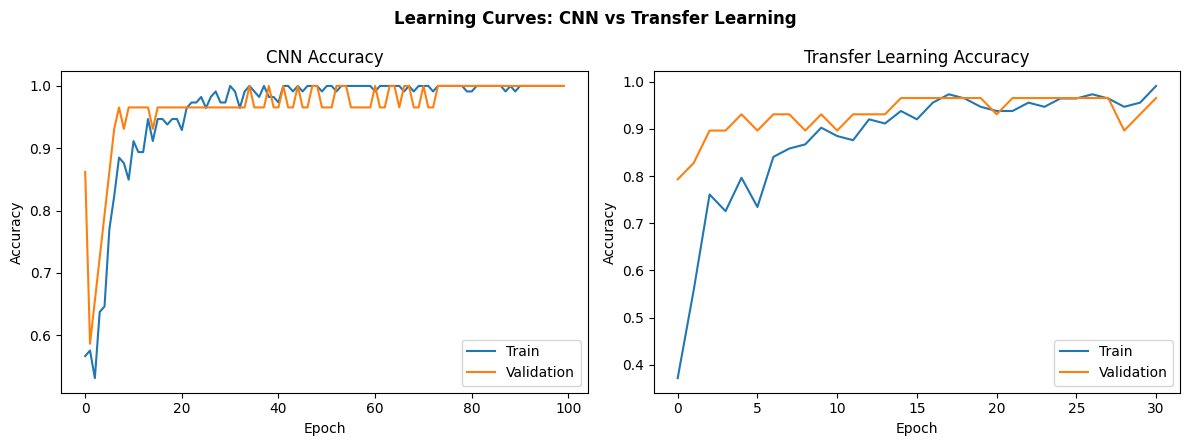

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, hist, title in zip(axes, [cnn_history, transfer_history], ["CNN Accuracy", "Transfer Learning Accuracy"]):
    ax.plot(hist.history["accuracy"], label="Train")
    ax.plot(hist.history["val_accuracy"], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
plt.suptitle("Learning Curves: CNN vs Transfer Learning", fontweight="bold")
plt.tight_layout()
plt.show()

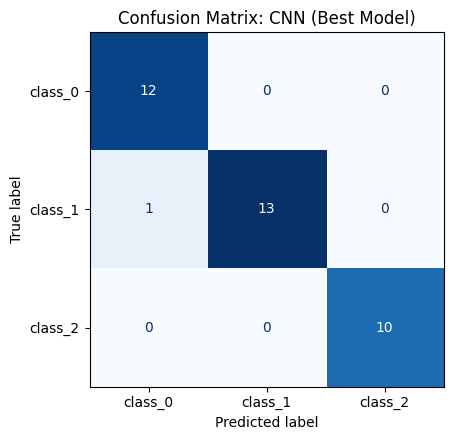

In [14]:
if transfer_accuracy >= cnn_accuracy:
    best_name, best_pred = "Transfer Learning", transfer_test_pred
else:
    best_name, best_pred = "CNN", cnn_test_pred

cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", ax=ax, colorbar=False)
plt.title(f"Confusion Matrix: {best_name} (Best Model)")
plt.tight_layout()
plt.show()

Best model: CNN | Correct: 35/36 | Wrong: 1/36


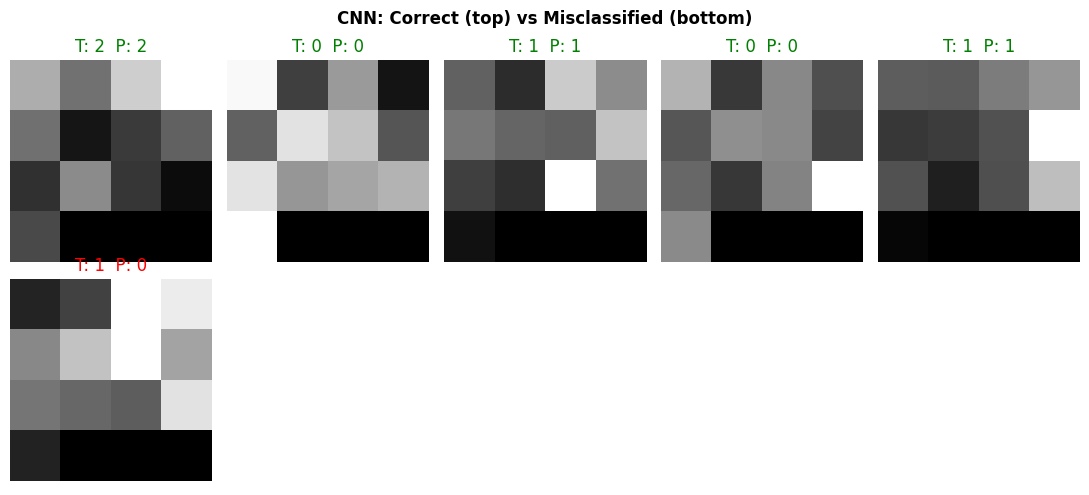

In [15]:
wrong = np.where(best_pred != y_test)[0]
right = np.where(best_pred == y_test)[0]
print(f"Best model: {best_name} | Correct: {len(right)}/{len(y_test)} | Wrong: {len(wrong)}/{len(y_test)}")

rng = np.random.RandomState(42)
sample_right = rng.choice(right, size=min(5, len(right)), replace=False)
sample_wrong = wrong[:5]

fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes[0], sample_right):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"T: {y_test[i]}  P: {best_pred[i]}", color="green")
for ax, i in zip(axes[1], sample_wrong):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"T: {y_test[i]}  P: {best_pred[i]}", color="red")
plt.suptitle(f"{best_name}: Correct (top) vs Misclassified (bottom)", fontweight="bold")
plt.tight_layout()
plt.show()

## **Discussion**

Write in your own words: which model got higher test accuracy, how many epochs each needed, and why. (Hint: Wine is tabular data with only 178 rows. The 4x4 'images' have no real spatial structure, so neighbouring pixels are unrelated chemical features. VGG16's ImageNet filters are built for real photos, so transfer learning has little to offer here.)

## **Exercises**

1. Compare both models with a simple baseline such as Logistic Regression or Random Forest on the raw 13 features.
2. Shuffle the order of the features before reshaping and see if CNN accuracy changes. What does that say about spatial structure?
3. Unfreeze the last VGG16 block and fine-tune with a low learning rate (1e-5).